##Notebook 2: Research Q1. Which acquisition channels produce higher conversion prospects at which rates, and how large is the difference between the channels

Input: Lead_Population_90d.csv
Approach:
1. check target balance
2. check for missing values
3. perform the chi square test on the conversion by origin, and Cramer V test

Output: a table displaying the conversion rate and chart by channel, followed with the chi-square test results, and Cramer V test

In [1]:
#The file generated at the end of 01_data_preperation notebook loaded correctly with all the rows and columns intact

import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('/content/Lead_Population_90d.csv')

df['first_contact_date'] = pd.to_datetime(df['first_contact_date'])
df['won_date'] = pd.to_datetime(df['won_date'])

print(df.shape)
print(df.head())

(6198, 9)
                             mql_id first_contact_date  \
0  dac32acd4db4c29c230538b72f8dd87d         2018-02-01   
1  b4bc852d233dfefc5131f593b538befa         2018-03-22   
2  6be030b81c75970747525b843c1ef4f8         2018-01-22   
3  5420aad7fec3549a85876ba1c529bd84         2018-02-21   
4  28bdfd5f057764b54c38770f95c69f2f         2018-01-14   

                    landing_page_id          origin            won_date  \
0  88740e65d5d6b056e0cda098e1ea6313          social                 NaT   
1  a7982125ff7aa3b2054c6e44f9d28522  organic_search                 NaT   
2  d45d558f0daeecf3cccdffe3c59684aa           email                 NaT   
3  b48ec5f3b04e9068441002a19df93c6c  organic_search 2018-02-26 19:58:54   
4  22c29808c4f815213303f8933030604c  organic_search                 NaT   

   converted_ever    month  days_to_convert  converted  
0               0  2018-02              NaN          0  
1               0  2018-03              NaN          0  
2               0  

converted
0    5514
1     684
Name: count, dtype: int64
conversion rate: 11.04 %


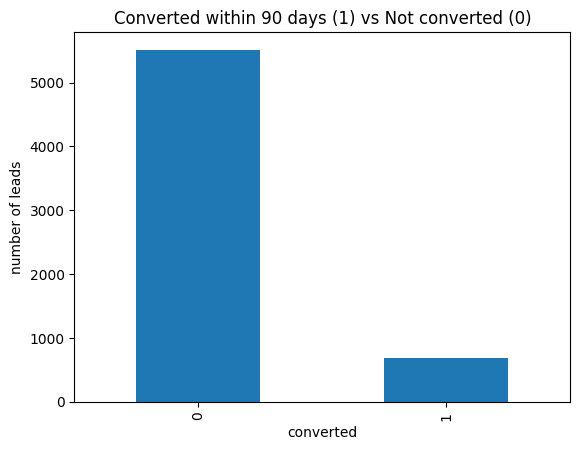

In [2]:
# From the 90 day target input file, only 11% of leads converted within the 90 day period, but predicting a "Not Converted" for every lead would be 89% accurate but useless

counts = df['converted'].value_counts()
print(counts)
print('conversion rate:', round(100 * df['converted'].mean(), 2), '%')

counts.plot(kind='bar')
plt.title('Converted within 90 days (1) vs Not converted (0)')
plt.xlabel('converted')
plt.ylabel('number of leads')
plt.show()

In [3]:
print(df.isna().sum())


mql_id                   0
first_contact_date       0
landing_page_id          0
origin                  51
won_date              5406
converted_ever           0
month                    0
days_to_convert       5406
converted                0
dtype: int64


In [4]:
#The missing values show that the origin column has 51 missing values, however I will keep the "missing" origin channels as they convert well in the data

df['origin'] = df['origin'].fillna('missing')
print(df['origin'].value_counts())


origin
organic_search       1796
paid_search          1217
social               1090
unknown               838
direct_traffic        390
email                 359
referral              220
other                 115
display                80
missing                51
other_publicities      42
Name: count, dtype: int64


In [5]:
#Now we look at the conversion rate by different channels, and we can see why I still decided to keep the "missing" origin channels as they convert well in the data.

origin_table = df.groupby('origin').agg(leads=('mql_id', 'size'),
                                        conv=('converted', 'sum'))
origin_table['rate'] = (100 * origin_table['conv'] / origin_table['leads']).round(1)
origin_table = origin_table.sort_values('rate', ascending=False)
print(origin_table)

                   leads  conv  rate
origin                              
missing               51    12  23.5
unknown              838   157  18.7
direct_traffic       390    50  12.8
paid_search         1217   148  12.2
organic_search      1796   216  12.0
referral             220    21   9.5
display               80     6   7.5
other_publicities     42     3   7.1
social              1090    55   5.0
other                115     4   3.5
email                359    12   3.3


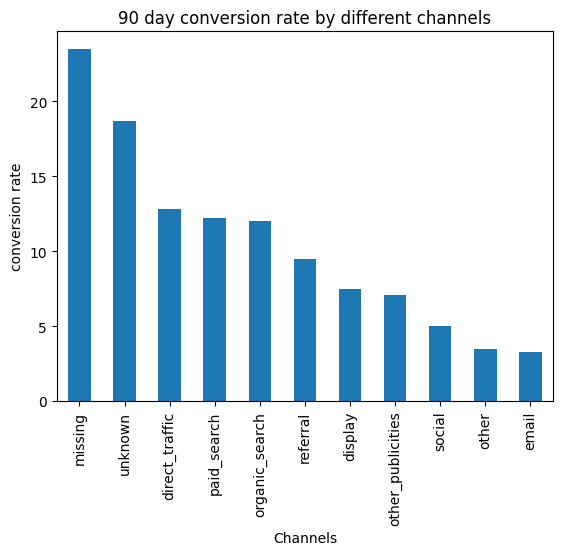

In [6]:
# Here is the bar chart of the visualization of the conversion rate by different channels

origin_table['rate'].plot(kind='bar')
plt.title('90 day conversion rate by different channels')
plt.xlabel('Channels')
plt.ylabel('conversion rate')
plt.show()


In [7]:
#When doing the chi test to understand the significance of the channels, x^2(chi-squared) = 133.7, and p is smaller than 0.5, so the difference between the channels are significant

table_origin = pd.crosstab(df['origin'], df['converted'])
result_origin = stats.chi2_contingency(table_origin)

print('chi-squared:', round(result_origin[0], 1))
print('df:', result_origin[2])
print('p-value:', round(result_origin[1], 3))

chi-squared: 133.7
df: 10
p-value: 0.0


In [8]:
#When doing the cramer V test, it reveals that although there is a diffrence between the channels, the association between them is weak

cramers_v = (result_origin[0] / len(df)) ** 0.5
print('Cramers V:', round(cramers_v, 3))

Cramers V: 0.147
